<a href="https://colab.research.google.com/github/JoseAlberto88/Hugging-Face-LLM-Course/blob/main/04_Sharing_Models_and_Tokenizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### The hugging Face Hub

The Hugging Face Hub; https://huggingface.co/  --our main website-- is the central platform that enables anyone to discover, use, and contribute new state-of-the-art models and datasets. It hosts a wide variety of models, with more that 10,000 publicly available. We'll focus on the models in this chapter, and take a look at the datasets in Chapter 5.

The models in the Hub are not limited to Transformers or even NLP. These are models from Flair: https://github.com/flairNLP/flair  and AllenNLP: https://github.com/allenai/allennlp for NLP, Asteroid: https://github.com/asteroid-team/asteroid and pyannote: https://github.com/pyannote/pyannote-audio for speech, and timm: https://github.com/huggingface/pytorch-image-models for vision, to name a few.

Each of this models is hosted in a Git repository, which allows versioning and reproducibility. Sharing a model on the Hub means opening it up to the community and making it accessible to anyone looking to easily use it, in turn eliminating their need to train a model on their own and simplifying sharing and usage.

Additionally, sharing a model in the Hub automatically deploys a hosted Inference API for that model. Anyone in the community is free to test it out directly on the model's page, with custom inputs and appropriate widgets.

The best part is that sharing and using any public model on the Hub is completely free! Paid plans: https://huggingface.co/pricing also exist if you wish to share models privately.

Having a huggingface.co account is required to follow allow this part, as we'll be creating and managing repositories on the Hugging Face Hub: create an account: https://huggingface.co/welcome




### Using pretrained models

The Model Hub makes selecting the appropriate model simple, so that using it in any downstream library can be done in a few lines of code. Let's take a took at how to actually use one of these models, and how to contribute back to the community.

Let's say we're looking for a French-based model that can perform mask filling.

We select the `camembert-base` checkpoint to try it out. The identifier `camembert-base` is all you need to start using it! As you've seen in the previous chapters, we can instantiate it using the `pipeline()` function:

In [1]:
from transformers import pipeline

camembert_fill_mask = pipeline("fill-mask", model="camembert-base")
results = camembert_fill_mask("Le camembert est <mask> :)")

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] CamembertForMaskedLM LOAD REPORT from: camembert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

In [2]:
print(results)

[{'score': 0.49091124534606934, 'token': 7200, 'token_str': 'délicieux', 'sequence': 'Le camembert est délicieux :)'}, {'score': 0.10556980222463608, 'token': 2183, 'token_str': 'excellent', 'sequence': 'Le camembert est excellent :)'}, {'score': 0.03453311696648598, 'token': 26202, 'token_str': 'succulent', 'sequence': 'Le camembert est succulent :)'}, {'score': 0.033031269907951355, 'token': 528, 'token_str': 'meilleur', 'sequence': 'Le camembert est meilleur :)'}, {'score': 0.03007640317082405, 'token': 1654, 'token_str': 'parfait', 'sequence': 'Le camembert est parfait :)'}]


As you can see, loading a model within a pipeline is extremely simple. The only thing that you need to watch out for is that the chosen checkpoint is suitable for the task it's going to be used for. For example, here we are loading the `camembert-base` checkpoint in the `fill-mask` pipeline, which is completely fine. But if we were to load this checkpoint in the `text-classification` pipeline, the results would not make sense because the head of `camembert-case` is not suitable for this task! We recommend using the task selector in the Hugging Face Hub interface in order to select the appropriate checkpoints:

You can also instantiate the checkpoint using the model architecture directly.

In [3]:
from transformers import CamembertTokenizer, CamembertForMaskedLM

tokenizer = CamembertTokenizer.from_pretrained("camembert-base")
model = CamembertForMaskedLM.from_pretrained("camembert-base")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] CamembertForMaskedLM LOAD REPORT from: camembert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


However, we recommend using the Auto*classes: https://huggingface.co/docs/transformers/model_doc/auto?highlight=auto#auto-classes instead, as these are by design architecture-agnostic. While the previous code sample limits users to checkpoints loadable in the CamemBERT architecture, using the `Auto*` classes makes switching checkpoints simple:  

In [4]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

tokenizer=AutoTokenizer.from_pretrained("camembert-base")
model=AutoModelForMaskedLM.from_pretrained("camembert-base")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] CamembertForMaskedLM LOAD REPORT from: camembert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### Sharing pretrained models

In the steps below, we'll take a look at the easiest ways to share pretrained models to the Hub. There are tools and utilities available that make it simple to share and update models directly on the Hub, which we will explore below.

We encourage all users that train models to contribute by sharing them with the community -sharing the models, even when trained on very specific datasets, will help others, saving them time and compute resources and providing access to useful trained artifacts. In turn, you can benefit from the work that others have done.

There are three ways to go about creating new models repositories:

  - Using the `push_to_hub` API.
  - Using the `huggingface_hub` Python library.
  - Using the web interface.

Once you've created a repository, you can upload files to it via git and git-Ifs. We'll walk you through creating model repositories and uploading files to them in the following sections.

### Using the push_to_hub API

The simplest way to upload files to the Hub is by leveraring the `push_to_hub` API.

Before going futher, you'll need to generate an authentication token so that the `huggingface_hub` API knows who you are and what namespaces you have write access to. Make sure you are in an enviroment where you have `transformers` installed. (See Setup: https://huggingface.co/learn/llm-course/chapter0/1). If you are in a notebook, you can use the following function to login:

In [5]:
from huggingface_hub import notebook_login

notebook_login()

In a terminal, you can run

```python
huggingface-cli login
```

In both cases, you should be prompted for your username and password, which are the same ones you use to login in to the Hub. If you don't have a Hub profile yet, you should create one here: https://huggingface.co/welcome.

Great! You now have your authentication token stored in your cache folder. Let's create some repositories!

If you have played around with the `Trainer` API to train a model, the easiest way to upload it to the Hub is to set `push_to_hub=True` when you define your `TrainingArguments`:

In [6]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    "bert-finetuned-mrpc", save_strategy="epoch", push_to_hub=True
)

When you call `trainer.train()`, the `Trainer` will then upload your model to the Hub each time it is saved (here every epoch) in a repository in your namespace. That repository will be named like the output directory you picked (here `bert-finetuned-mrpc`) but you can choose a different name with `hub_model_id = "a_different_name"`.

To upload your model to an organization you are a member of, just pass it with `hub_model_id = "my_organization/my_repo_name"`.

Once your traininh is finished, you should do a final `trainer.push_to_hub` to upload the last version of your model. It will also generate a model card with all the relevant metadata, reporting the hyperparameters used and the evaluation results! Here is an example of the content you might find in such a model card:

## Training procedure

### Training hyperparameters

The following hyperparameters were used during training:

- learning_rate: 5e-05
- train_batch_size: 32
- eval_batch_size: 32
- seed: 42
- distributed_type: multi-GPU
- num_devices: 2
- total_train_batch_size: 64
- total_eval_batch_size: 64
- optimizer: Adam with betas=(0.9,0.999) and epsilon=1e-08
- lr_scheduler_type: linear
- num_epochs: 3.0
- mixed_precision_training: Native AMP

### Training results

| Training Loss | Epoch | Step | Validation Loss | Accuracy | F1       | Combined Score |
|:-------------:|:-----:|:----:|:---------------:|:--------:|:--------:|:--------------:|
| 0.6093        | 1.0   | 58   | 0.542145        | 0.727941 | 0.833083 | 0.780512       |
| 0.4107        | 2.0   | 116  | 0.391782        | 0.816176 | 0.859813 | 0.837995       |
| 0.2512        | 3.0   | 174  | 0.419665        | 0.852941 | 0.896907 | 0.874924       |


At a lower level, accessing the Model Hub can be done directly on models, tokenizers, and configuration objects via their `pust_to_hub()` method. This method takes care of both the repository creation and pushing the model and tokenizer files directly to the repository. No manual handling is required, unlike with the API we'll see below.

To get an idea of how it works, let's first initialize a model and a tokenizer:

In [7]:
from transformers import AutoModelForMaskedLM, AutoTokenizer

checkpoint = "camembert-base"

model = AutoModelForMaskedLM.from_pretrained(checkpoint)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] CamembertForMaskedLM LOAD REPORT from: camembert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


You're free to do whatever you want with these -add tokens to the tokenizer, train the model, fine-tune it. Once you've happy with the resulting model, weights, and tokenizer, you can leverage the `push_to_hub()` method directly available in the `model` object:

In [8]:
model.push_to_hub("dummy-model")

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...h2bzn6j/model.safetensors:   0%|          |  148kB /  443MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/JoseA1988/dummy-model/commit/6139981c041efdfc22ae07fc7d60edea0bc2ef66', commit_message='Upload CamembertForMaskedLM', commit_description='', oid='6139981c041efdfc22ae07fc7d60edea0bc2ef66', pr_url=None, repo_url=RepoUrl('https://huggingface.co/JoseA1988/dummy-model', endpoint='https://huggingface.co', repo_type='model', repo_id='JoseA1988/dummy-model'), pr_revision=None, pr_num=None)

This will create the new repository `dummy-model` in your profile, and populate it with your model files. Do the same with the tokenizer, so that all the files are now available in this repository:

In [9]:
tokenizer.push_to_hub("dummy-model")

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/JoseA1988/dummy-model/commit/6139981c041efdfc22ae07fc7d60edea0bc2ef66', commit_message='Upload tokenizer', commit_description='', oid='6139981c041efdfc22ae07fc7d60edea0bc2ef66', pr_url=None, repo_url=RepoUrl('https://huggingface.co/JoseA1988/dummy-model', endpoint='https://huggingface.co', repo_type='model', repo_id='JoseA1988/dummy-model'), pr_revision=None, pr_num=None)

If you belong to an organization, simply specify the `organization` argument to upload to that organization's namespace:

```python
tokenizer.push_to_hub("dummy-model", organization="huggingface")
```

If you with you use a specific Hugging Face token, you're free to specify it to the `push_to_hub()` method as well:

```python
tokenizer.push_to_hub("dummy-model", organization="huggingface", use_auth_token="<TOEKN>")
```

Now head to the Model Hub to find your newly uploaded model: : https://huggingface.co/user-or-organization/dummy-model.

Click on the "Files and versions" tab, and you should see the files visible in the fillowing screenshot:

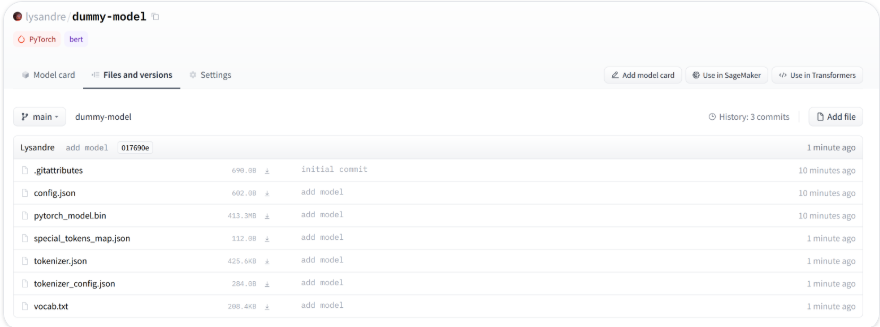


As you've seen, the `push_to_hub()` method accepts several arguments, making it possible to upload to a specific repository or organization namespace, or to use a different API token. We recommend you take a look at the method specification available directly in the Transformers documentation: https://huggingface.co/docs/transformers/model_sharing to get an idea of what is possible.

The `push_to_hub()` method is backed by the huggingface_hub: https://github.com/huggingface/huggingface_hub Python package, which offers a direct API to the Hugging Face Hub. It's integrated within Transformers and several other machine learning libraries, like allenlp: https://github.com/allenai/allennlp. Although we focus in the Transformers integration in this chapter, integrating it into your own code or library is simple.

Jump to the last section to see how to update files to your newly created repository!




### Using the huggingface_hub Python library

The `huggingface_hub` Python library is a package which offers a set of tools for the model and datasets hubs. It provides simple methods and classes for common tasks like getting information about repositories on the hub and managing them. It provides simple APIs that work on top of git to manage those repositories' content and to integrate the Hub in your projects and libraries.

Similarly to using the `push_to_hub` API, this will require you to have your API token saved in your cache. In order to do this, you will need to use the `login` command from the CLI, as mentioned in the previous section (again, make sure to prepend these commands with the `!` character if running in Google Colab):


```python
huggingface-cli login
```

The `huggingface_hub` packages offers several methods and classes which are useful for our purpose. Firstly, there are a few methods to manage repository creation, deletion, and others:

In [10]:
from huggingface_hub import (
    # User management
    login,
    logout,
    whoami,

    # Repository creation and management
    create_repo,
    delete_repo,
    update_repo_settings,

    # Retrieve or change information about the content
    list_models,
    list_datasets,
    list_repo_files,
    upload_file,
    delete_file,
)

Additionally, it offers the very powerful `Repository` class to manage a local repository. We will explore these methods and that class in the next few section to understand how to leverage them.

The `create_repo` method can be used to create a new repository on the hub:

In [12]:
from huggingface_hub import create_repo

create_repo("dummy-mode2")

RepoUrl('https://huggingface.co/JoseA1988/dummy-mode2', endpoint='https://huggingface.co', repo_type='model', repo_id='JoseA1988/dummy-mode2')

This will create the repository `dummy-model1` in your namespace. If you like, you can specify which organization the repository should belong to using the `organization` argument:

```python
from huggingface_hub import create_repo

create_repo("dummy-model3", organization="huggingface")
```

This will create the `dummy-model3` repository in the `huggingface` namespace, assuming you belong to that organization. Other arguments which may be useful are:

  - `private`, in order to specify if the repository should be visible from others or not.
  - `token`, if you would like to override the token stored in your cache by a given token.
  - `repo_type`, if you would like to create a `dataset` or a `space` instead of a model. Accepted values are `"dataset"` and `"space"`.

Once the repository is created, we should add files to it! Jump to the next section to see the three ways this can be handled.

### Using the web interface

The web interface offers tools to manage repositories directly in the Hub. Using the interface, you can easily create repositories, add files (even large ones!), explore models, visualize diffs, and much more.

To create a new repository, visit: https://huggingface.co/new

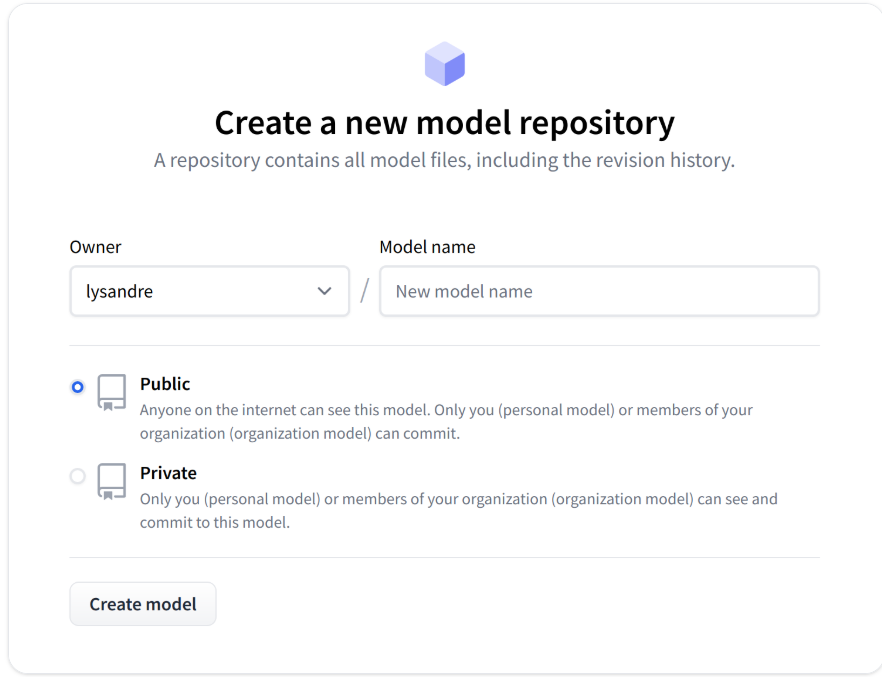

First, specify the owner of the repository: this can be either you or any of the organizations you're affiliated with. If you choose an organization, the model will be featured on the organization's page and every member of the organization will have the ability to contribute to the repository.

Next, enter your model's name. This will also be the name of the repository. Finally, you can specify whether you want your model to be public or private. Private models are hidden from the public view.

After creating your model repository, you should see a page like this:

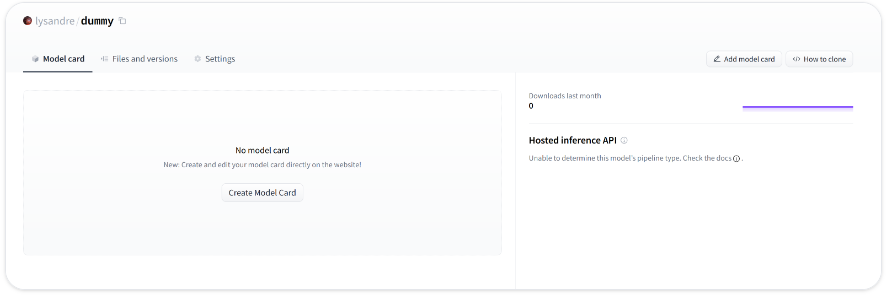

This is where your model will be hosted. To start populating it, you can add a README file directly from the web interface.

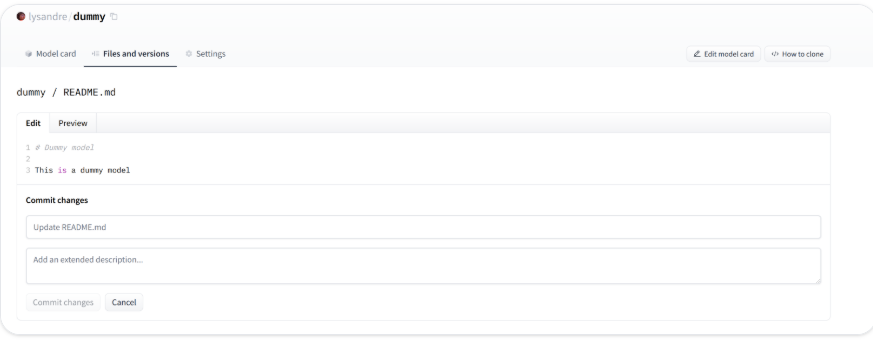

The README file is a Markdown -feel free to go with it! The third part of this chapter is dedicated to building a model card. These are of prime importance in bringing value to your model, ad they're where you tells others what it can do.

If you look at the "Files and versions" tab, you'll see that there aren't many files there yet -just the *README.md* you just created and the *.gitattributes* file that keeps track of large files.

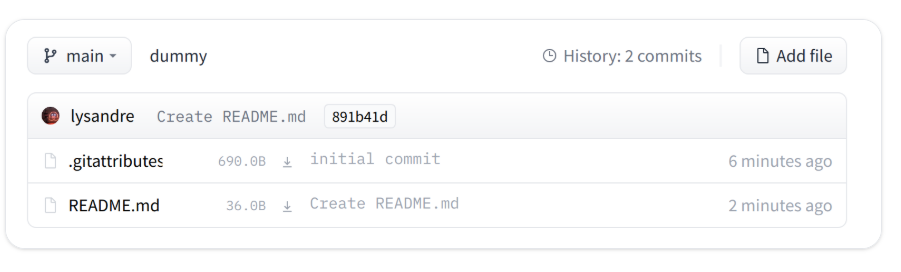

We'll take a look at how to add some new files next.

### Uploading the model files

The system to manage files on the hugging face hub is based on git for regular files, and git-Ifs (which stands for Git Large File Storage: https://git-lfs.com/ ) for larger files.

In the next section, we go over three different ways of uploading files to the Hub: through `huggingface_hub` and through git commands.

### The upload_file approach

Using `upload_file` does not require git and git-Ifs to be installed on your system. It pushes files directly to the Hub using HTTP POST requests. A limitation of this approach is that it doesn't handle files that are larger than 5GB in size. If your files are larger than 5GB, please follow the two other methods detailed below.

The API may be used as follows:

```python
from huggingface_hub import upload_file

upload_file(
  "<path_to_file>/config.json",
  path_in_repo="config.json",
  repo_id="<namespace>/dummy-model"
)
```

This will upload the file `config.json` available at `<path_to_file>` to the root of the repository as `config.json`, to the `dummy-model` repository. Other areguments which may be useful are:

  - `token`, if you would like to override the token stored in your cache by a given token.
  - `repo_type`, if you would like to update to a `dataset` or a `space` instead of a model. Accepted values are `"dataset"` and `"space"`.

### The repository class

The `Repository` class manages a local repository in a git-like manner. It abstracts most of the pain points one may have with git to provide all features that we require.

Using this class requires having git and git-Ifs installed, so make sure you have git-Ifs installed (see here: https://git-lfs.com/ for installation instructions) and set up before you begin.

In order to start playing around with the repository we have just created, we can start by initialising it into a local folder by cloning the remore repository:

```python
from huggingface_hub import Repository

repo = Repository("<path_to_dummy_folder>", clone_from = "<namespace>/dummy-model" )
```

This created the folder `<path_to_dummy_folder>` in our working directory. This folder only contains the `.gitattributes` file as that's the only file created when instantialing the repository through `create_repo`.

From this point on, we may leverage several of the traditional git methods:

```python
repo.git_pull()
repo.git_add()
repo.git_commit()
repo.git_push()
repo.git_tag()
```

And others! We recommend taking a look at the `Repository` documentation available here: https://github.com/huggingface/huggingface_hub/tree/main/src/huggingface_hub#advanced-programmatic-repository-management for an overview of all available methods.

At present, we have a model and a tokenizer that we would like to push to the hub. We have successfully cloned the repository, we can therefore save the files within that repository.

We first make sure that our local clone is up to date by pulling the latest changes:

```python
repo.git_pull()
```

Once that is done, we save the model and tokenizer files:

```python
model.save_pretrained("<path_to_dummy_folder>")
tokenizer.save_pretrained("<path_to_dummy_folder>")
```

The `<path_to_dummy_folder>` now contains all the model and tokenizer files. We follow the usual git workflow by adding files to the staging area, committing them and pushing them to the hub:

```python
repo.git_add()
repo.git_commit("Add model and tokenizer files")
repo.git_push()
```

Comgratulations! You just pushed your first files on the hub.